# Day 22: Deep Learning Mini-Project & Checkpoint

Today **you** build and train a small neural network, alone, from start to end.

**Checkpoint:** at the end of today you can say:
> "I understand what this code is doing, and I can train a small neural network."

| Part | What you do | Time |
|---|---|---|
| A | Read code and explain each line | 25 min |
| B | Mini-project: predict exam results | 75 min |
| C | Experiments: change settings, compare | 25 min |
| D | Answer 6 short questions | 15 min |
| ✅ | Checkpoint list | 5 min |

**Rules:** You can look at your old notebooks. Ask the teacher only after you try for 5 minutes.

In [56]:
import numpy as np                                     # arrays of numbers
import pandas as pd                                    # tables (read CSV files)
import matplotlib.pyplot as plt                        # charts
import torch                                           # PyTorch: tensors + training
from torch import nn                                   # layers, ReLU, loss functions
from sklearn.model_selection import train_test_split   # split into train / validation / test
from sklearn.preprocessing import StandardScaler       # make columns the same scale

---
# Part A: Read the code and explain it

This code trains a small network on **loans.csv**: will the bank **approve** the loan (1) or not (0)?

**Your task:** run it. Then, in the next cell, write a short comment **after every line**: what does this line do?

In [57]:
loans = pd.read_csv("loans.csv")
X = loans[["monthly_income", "loan_amount"]].values 
y = loans[["approved"]].values 

X = StandardScaler().fit_transform(X) 
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32)

torch.manual_seed(42)
model = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 1), nn.Sigmoid())
loss_fn = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(100):
    guess = model(X)
    loss = loss_fn(guess, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("final loss:", round(loss.item(), 3))

final loss: 0.452


In [58]:
# Copy the code here and write a comment after EVERY line.
# Example:  loans = pd.read_csv("loans.csv")    # read the table from the file
loans = pd.read_csv("loans.csv")  # assign the loans.csv file in loans variable

X = loans[["monthly_income", "loan_amount"]].values  # the values of 2 features (monthly_income, loan_amount) of loans assigned to the x variable

y = loans[["approved"]].values  # the values of the approved feature is assigned to the y variable

X = StandardScaler().fit_transform(X)  # scale features to mean=0, std=1

X = torch.tensor(X, dtype=torch.float32)  # features of X varibles to be converted as a float32 tensor

y = torch.tensor(y, dtype=torch.float32)  # features of Y varibles to be converted as a float32 tensor

torch.manual_seed(42)  # fix random seed for reproducibility

model = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 1), nn.Sigmoid())  # define the neural network

# Build a small neural network:
# - Linear(2 -> 8): hidden layer mapping the 2 input features to 8 units
# - ReLU(): non-linear activation
# - Linear(8 -> 1): output layer producing a single logit
# - Sigmoid(): squashes the logit into a probability in [0, 1]

loss_fn = nn.BCELoss()  # loss function for binary classification

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)  # optimizer for weight updates. Adam optimizer updates the model's weights using gradients, with learning rate 0.01

for epoch in range(100):  # Training loop: run 100 full passes (epochs) over the dataset ,iterate 100 epochs
    guess = model(X)  # forward pass to get predictions

    loss = loss_fn(guess, y)  # compute loss between predictions and targets

    optimizer.zero_grad()  # reset gradients to zero

    loss.backward()  # backpropagate gradients

    optimizer.step()  # update weights using the optimizer

print("final loss:", round(loss.item(), 3))  # display the final loss value

final loss: 0.452


**✏️ Questions about Part A** (write your answer in the cell below each one)

1. Why does this model end with `nn.Sigmoid()`?
2. Why do we use `BCELoss` here?
3. In Part B we predict **3** results. Which last layer and which loss will we use there?

*Your answers:*

1. Because sigmoid turns the logit into the probability. 
2. To count the loss from the taget.
3. The last layer will be nn.Linear(inputs, 3) and the cross entropy loss function will be used as the there are multiple classes as the output.

---
# Part B: Mini-project: predict exam results

A college in Lahore wants to know early which students need help.
For **400 students** they have 5 numbers and the final **result**.

| Column | Meaning |
|---|---|
| `study_hours` | hours of study per day (0 to 6) |
| `attendance_pct` | attendance in % (40 to 100) |
| `assignments_done` | assignments done, out of 10 |
| `sleep_hours` | hours of sleep per night |
| `phone_hours` | hours on the phone per day |
| `result` | **0 = Fail, 1 = Pass, 2 = Distinction** |

**Goal:** train a network that guesses `result`. Then check it on the test students.

These 2 classes are the same as in class. **Run this cell, do not change it.**

In [59]:
class Net(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs):
        super().__init__()                          # start the nn.Module part
        self.hidden = nn.Linear(n_inputs, n_hidden) # input → hidden (weights + biases)
        self.relu = nn.ReLU()                       # activation: negative → 0
        self.output = nn.Linear(n_hidden, n_outputs)# hidden → output

    def forward(self, x):
        return self.output(self.relu(self.hidden(x)))


class Trainer:
    def __init__(self, model, loss_fn, lr):
        self.model = model
        self.loss_fn = loss_fn
        self.optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        self.train_losses, self.val_losses = [], []

    def fit(self, X_train, y_train, X_val, y_val, epochs):
        for epoch in range(epochs):
            loss = self.loss_fn(self.model(X_train), y_train)   # 1. guess + 2. how wrong
            self.optimizer.zero_grad()                          # 3. clear old blame
            loss.backward()                                     # 4. find blame (backprop)
            self.optimizer.step()                               # 5. fix (gradient descent)
            self.train_losses.append(loss.item())
            with torch.no_grad():                               # mock exam: check only
                self.val_losses.append(self.loss_fn(self.model(X_val), y_val).item())

    def predict(self, X):
        with torch.no_grad():
            return self.model(X)

    def plot(self):
        plt.plot(self.train_losses, label="train (homework)")
        plt.plot(self.val_losses, label="validation (mock exam)")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.show()

## Step 1: Load and look

- Read `exam_results.csv` into `exams`.
- Print the first 5 rows and the shape.
- Count how many students are in each result with `.value_counts()`.

In [60]:
# your code here
exams = pd.read_csv("exam_results.csv")
print(exams.shape)
print(exams.head(5))

(400, 6)
   study_hours  attendance_pct  assignments_done  sleep_hours  phone_hours  \
0          3.8              60                 6          8.3          3.5   
1          5.4              96                10          8.4          2.0   
2          4.7              49                 6          7.1          5.7   
3          1.4              71                 1          6.6          5.8   
4          1.8              45                10          5.0          6.6   

   result  
0       1  
1       2  
2       1  
3       0  
4       0  


## Step 2: X and y

- `X` = the 5 input columns (everything **except** `result`). Hint: `exams.drop(columns="result")`
- `y` = the `result` column.
- Use `.values` on both.

In [72]:
# your code here
X = exams.drop(columns="result").values
print(X)
y = exams[["result"]].values
print(y)

[[ 3.8 60.   6.   8.3  3.5]
 [ 5.4 96.  10.   8.4  2. ]
 [ 4.7 49.   6.   7.1  5.7]
 ...
 [ 1.  74.  10.   7.7  6.5]
 [ 5.5 84.   4.   4.9  5.9]
 [ 3.6 81.   2.   4.5  1.4]]
[[1]
 [2]
 [1]
 [0]
 [0]
 [2]
 [0]
 [2]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [0]
 [1]
 [2]
 [1]
 [1]
 [2]
 [0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [1]
 [2]
 [1]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [1]
 [0]
 [2]
 [1]
 [1]
 [0]
 [1]
 [1]
 [2]
 [0]
 [2]
 [1]
 [1]
 [1]
 [0]
 [1]
 [0]
 [2]
 [1]
 [1]
 [1]
 [2]
 [0]
 [0]
 [0]
 [1]
 [0]
 [2]
 [0]
 [1]
 [0]
 [2]
 [1]
 [0]
 [2]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [2]
 [1]
 [1]
 [0]
 [1]
 [0]
 [0]
 [2]
 [2]
 [1]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [2]
 [2]
 [1]
 [1]
 [2]
 [0]
 [1]
 [0]
 [0]
 [1]
 [2]
 [2]
 [0]
 [2]
 [0]
 [2]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [2]
 [0]
 [0]
 [0]
 [2]
 [0]
 [1]
 [0]
 [2]
 [2]
 [2]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [2]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [2]
 [1]
 [0]
 [1]
 

## Step 3: Split 60 / 20 / 20

Homework (train), mock exam (validation), final exam (test). Use `random_state=42` both times.

In [62]:
# your code here
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42)
print("train:", len(X_train), " validation:", len(X_val), " test:", len(X_test))

train: 240  validation: 80  test: 80


## Step 4: Scale

- `attendance_pct` is 40 to 100, `sleep_hours` is 4 to 9. Big numbers would push the weights too much.
- Make a `StandardScaler`. **Fit it on train only**, then transform train, val and test.
- Why train only? The test students are the "final exam". We must not peek at them.

In [63]:
# your code here
scaler = StandardScaler().fit(X_train) 

X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)


## Step 5: Tensors

- Inputs → `torch.float32` (decimals).
- Answers → `torch.long` (whole numbers), because `CrossEntropyLoss` wants the class number 0, 1, 2.

In [82]:
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_val_t   = torch.tensor(X_val_s,   dtype=torch.float32)
X_test_t  = torch.tensor(X_test_s,  dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.long).squeeze(1)   # (240,) ← FIX
y_val_t   = torch.tensor(y_val,   dtype=torch.long).squeeze(1)   # (80,)  ← FIX
y_test_t  = torch.tensor(y_test,  dtype=torch.long).squeeze(1)   # (80,)  ← add this too

## Step 6: Build and train

- Model: `Net` with **5 inputs, 16 hidden, 3 outputs**. Write `torch.manual_seed(42)` first.
- Loss: `nn.CrossEntropyLoss()`. Learning rate `0.01`.
- Train **100 epochs** with `Trainer`, then `.plot()` the losses.

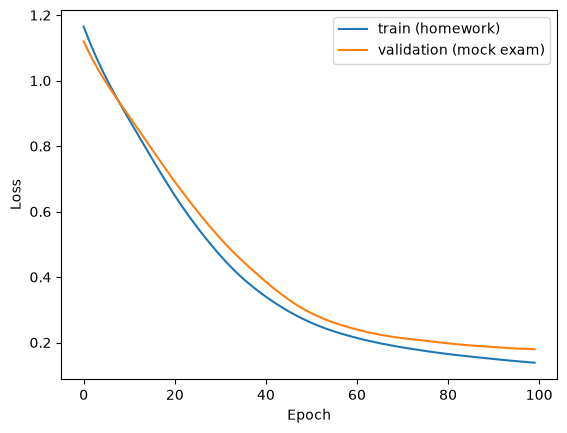

In [83]:
# your code here
torch.manual_seed(42)
model   = Net(n_inputs=5, n_hidden=16, n_outputs=3)
trainer = Trainer(model, nn.CrossEntropyLoss(), lr=0.01)
trainer.fit(X_train_t, y_train_t, X_val_t, y_val_t, epochs=100)
trainer.plot()

**✏️ Look at your plot:** do both lines go down? Does the validation line stop going down or go up at the end?

*Your answer:*

## Step 7: Evaluate

- Guess for the **train** and **test** students: `trainer.predict(...)`, then `.argmax(dim=1)`.
- Accuracy = correct ÷ total. Print both.
- Make a table of real vs guessed with `pd.crosstab(y_test, test_guess)`.

In [84]:
# your code here
train_guess = trainer.predict(X_train_t).argmax(dim=1).numpy()
test_guess  = trainer.predict(X_test_t ).argmax(dim=1).numpy()

train_acc = (train_guess == y_train_t.numpy()).mean()
test_acc  = (test_guess  == y_test_t.numpy() ).mean()
print(f"Train accuracy: {train_acc:.1%}")
print(f"Test  accuracy: {test_acc:.1%}")

print(pd.crosstab(y_test_t.numpy(), test_guess,
                  rownames=["real"], colnames=["guessed"]))

Train accuracy: 96.2%
Test  accuracy: 82.5%
guessed   0   1   2
real               
0        25   0   0
1         6  30   6
2         0   2  11


**✏️ Questions:**
1. Is test accuracy lower than train accuracy? What does that mean?
2. In the table, which mistakes happen most? (Fail ↔ Pass, Pass ↔ Distinction, or Fail ↔ Distinction?)

*Your answers:*

1.
2.

## Step 8: Predict for new students

| Name | study | attendance | assignments | sleep | phone |
|---|---|---|---|---|---|
| Ali | 5.0 | 90 | 9 | 7.5 | 1.0 |
| Sara | 1.0 | 55 | 2 | 5.0 | 6.0 |

- Put them in a table (2 rows × 5 numbers).
- **Scale with the same `scaler`** (only `.transform`).
- Tensor → `trainer.predict` → `torch.softmax(..., dim=1)` to see the chances.

In [85]:
# your code here
new_students = pd.DataFrame({
    "study_hours":      [5.0, 1.0],
    "attendance_pct":   [90,  55],
    "assignments_done": [9,   2],
    "sleep_hours":      [7.5, 5.0],
    "phone_hours":      [1.0, 6.0],
}, index=["Ali", "Sara"])

new_scaled = scaler.transform(new_students)                 # same scaler, only .transform
new_t      = torch.tensor(new_scaled, dtype=torch.float32)
logits     = trainer.predict(new_t)
probs      = torch.softmax(logits, dim=1)

print(pd.DataFrame(probs.numpy(),
                   index=new_students.index,
                   columns=["Fail", "Pass", "Distinction"]).round(3))

      Fail  Pass  Distinction
Ali    0.0   0.0          1.0
Sara   1.0   0.0          0.0


c:\Users\Arham\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


---
# Part C: Experiments

One setting at a time. Run `run(...)` and **write the numbers in the table**.

In [68]:
def run(n_hidden=16, lr=0.01, epochs=100):
    torch.manual_seed(42)
    model = Net(5, n_hidden, 3)
    trainer = Trainer(model, nn.CrossEntropyLoss(), lr=lr)
    trainer.fit(X_train_t, y_train_t, X_val_t, y_val_t, epochs=epochs)
    train_acc = (trainer.predict(X_train_t).argmax(dim=1).numpy() == y_train).mean()
    test_acc = (trainer.predict(X_test_t).argmax(dim=1).numpy() == y_test).mean()
    print(f"hidden={n_hidden}, lr={lr}, epochs={epochs} → train {train_acc:.1%}, test {test_acc:.1%}")

run()   # our model from Part B

hidden=16, lr=0.01, epochs=100 → train 35.4%, test 36.6%


In [86]:
# Try these one by one:
run(lr=0.001)
run(lr=0.1)
run(n_hidden=4)
run(n_hidden=64)
run(epochs=20)
run(epochs=300)

hidden=16, lr=0.001, epochs=100 → train 33.9%, test 35.5%
hidden=16, lr=0.1, epochs=100 → train 35.5%, test 36.5%
hidden=4, lr=0.01, epochs=100 → train 35.6%, test 37.6%
hidden=64, lr=0.01, epochs=100 → train 35.4%, test 37.7%
hidden=16, lr=0.01, epochs=20 → train 35.1%, test 36.1%
hidden=16, lr=0.01, epochs=300 → train 35.4%, test 38.0%


| Change | Train acc | Test acc | What happened? |
|---|---|---|---|
| normal (16, 0.01, 100) | | | |
| lr = 0.001 | | | |
| lr = 0.1 | | | |
| hidden = 4 | | | |
| hidden = 64 | | | |
| epochs = 20 | | | |
| epochs = 300 | | | |

---
# Part D: Short questions

Answer in 1–2 lines each.

1. What does **one epoch** mean?
2. What do `loss.backward()` and `optimizer.step()` do?
3. Why do we split off **test** data and never train on it?
4. Why did we **scale** the columns?
5. Why is there **no softmax layer** in our `Net`?
6. Train 96%, test 82%. What is the name for this gap, and give one way to make it smaller.

*Your answers:*

1. One epoch means the model has looked at the entire dataset exactly once. We loop 100 times so the model gets 100 full passes to learn from the data.
2. loss.backward() figures out how wrong the model was and which weights caused the error. optimizer.step() then nudges those weights a little to make the error smaller next time.
3. We keep test data hidden so we can check if the model actually learned general patterns, not just memorized the training answers. Training on it would be like giving a student the exam answers before the test.
4. Scaling puts all features on the same size range (like income in thousands vs. loan amount in hundreds) so no single column unfairly dominates learning. It also helps the optimizer converge faster and more stably.
5. Softmax is for choosing between many classes (like cat vs. dog vs. bird). Here we only have two outcomes (approved / not approved), so a single sigmoid output is enough.
6. This gap is called overfitting — the model memorized the training data but doesn't generalize well. One easy fix: add regularization (like dropout or weight decay) or collect more training data so the model can't just memorize.

---
# ✅ Checkpoint

Tick each line only if it is true. Show the teacher.

- [ ] I can explain what every line of the Part A code does.
- [ ] I can load a CSV and make X and y.
- [ ] I can split into train / validation / test and scale with train only.
- [ ] I can make tensors (float32 for inputs, long for classes).
- [ ] I can build a `Net`, train it with `Trainer`, and read the loss plot.
- [ ] I can work out accuracy on test data.
- [ ] I know when to use Sigmoid + BCELoss and when to use CrossEntropyLoss.
- [ ] I can predict for a new person (scale first!).

---
# 🏠 Problem

Same steps, **yes/no** problem: will the bank approve the loan? Use `loans.csv`.

1. X = `monthly_income`, `loan_amount`, `years_in_job`, `has_defaulted_before`. y = `approved`.
2. Split 60 / 20 / 20, scale with train only.
3. Tensors: X **float32**, y **float32** with shape (n, 1). (BCELoss wants decimals.)
4. Model: `nn.Sequential(nn.Linear(4, 8), nn.ReLU(), nn.Linear(8, 1), nn.Sigmoid())`, loss `nn.BCELoss()`, 100 epochs.
5. Guess = chance > 0.5. Print the test accuracy.
6. Write 2 lines: what changed compared with the exam project, and why?